# 01 - Exploratory analysis & statistics: Rossmann store sales

Questions: what is the trend and seasonality, how much do promos and holidays move sales, and is the promo lift
statistically real (not just visible)? Input is the **cleaned** panel produced by `src/pipeline`.
Closed days (`open = 0`) are excluded from every sales statistic: they are structural zeros, not demand.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
panel = pd.read_parquet(ROOT / "data/processed/sales.parquet")
stores = pd.read_parquet(ROOT / "data/processed/stores.parquet")
op = panel[(panel.open == 1)].copy()
print(f"{panel.store.nunique():,} stores, {panel.date.min().date()} -> {panel.date.max().date()}, "
      f"{len(op):,} open store-days ({len(op)/len(panel):.1%} of the panel)")

1,115 stores, 2013-01-01 -> 2015-07-31, 844,338 open store-days (80.4% of the panel)


## 1. Trend

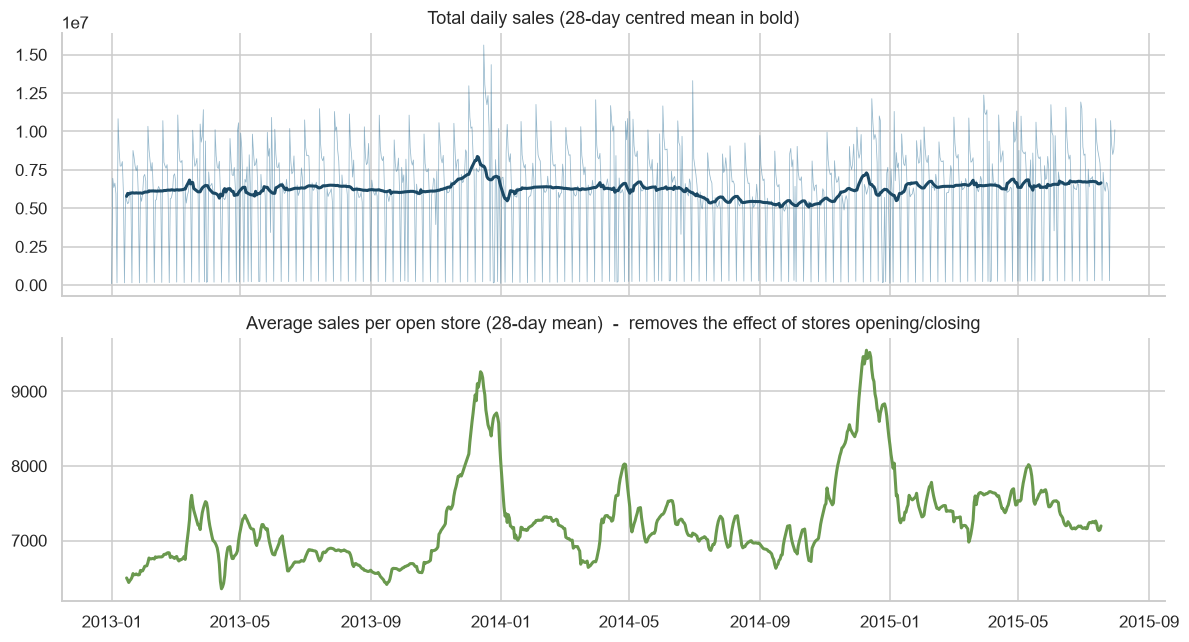

Mean sales per open store-day, Jan-Jul only (like-for-like):
year
2013    6703.0
2014    6878.0
2015    7088.0
YoY growth, same months: {2014: '2.6%', 2015: '3.1%'}


In [2]:
daily = op.groupby("date").agg(total_sales=("sales", "sum"), open_stores=("store", "nunique"))
daily["sales_per_open_store"] = daily.total_sales / daily.open_stores
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(daily.index, daily.total_sales, lw=.5, alpha=.5, color="#2a6f97")
ax[0].plot(daily.index, daily.total_sales.rolling(28, center=True).mean(), color="#1b4965", lw=2)
ax[0].set_title("Total daily sales (28-day centred mean in bold)")
ax[1].plot(daily.index, daily.sales_per_open_store.rolling(28, center=True).mean(), color="#6a994e", lw=2)
ax[1].set_title("Average sales per open store (28-day mean)  -  removes the effect of stores opening/closing")
fig.tight_layout(); fig.savefig(FIG / "eda_trend.png", dpi=130); plt.show()

yr = op.assign(year=op.date.dt.year).groupby("year").sales.mean()
jan_jul = op[op.date.dt.month <= 7].assign(year=lambda d: d.date.dt.year).groupby("year").sales.mean()
growth = jan_jul.pct_change().dropna()
print("Mean sales per open store-day, Jan-Jul only (like-for-like):")
print(jan_jul.round(0).to_string())
print("YoY growth, same months:", {int(k): f"{v:.1%}" for k, v in growth.items()})

## 2. Weekly and yearly seasonality

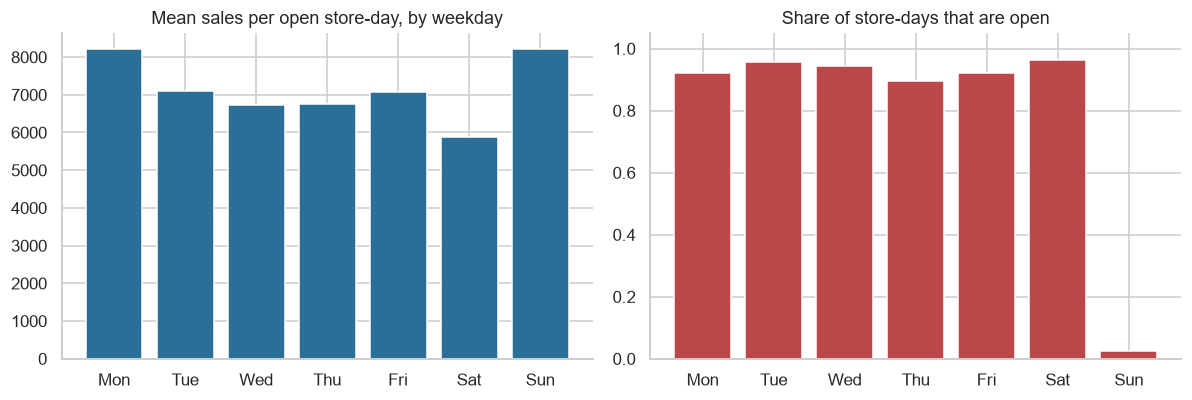

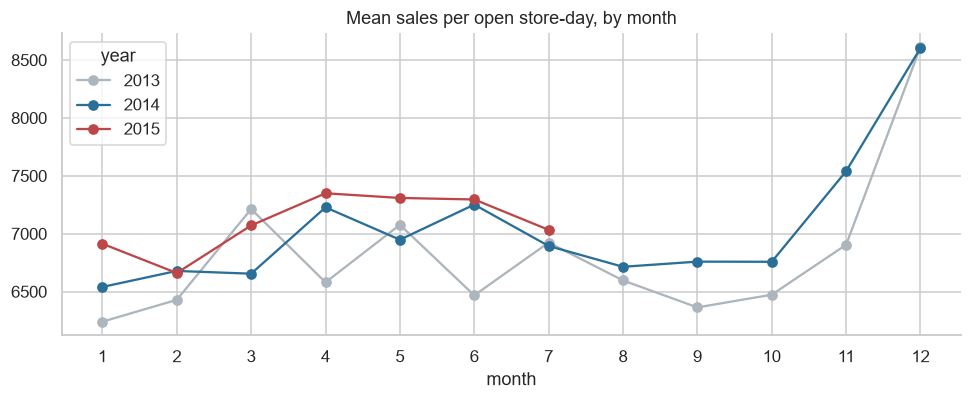

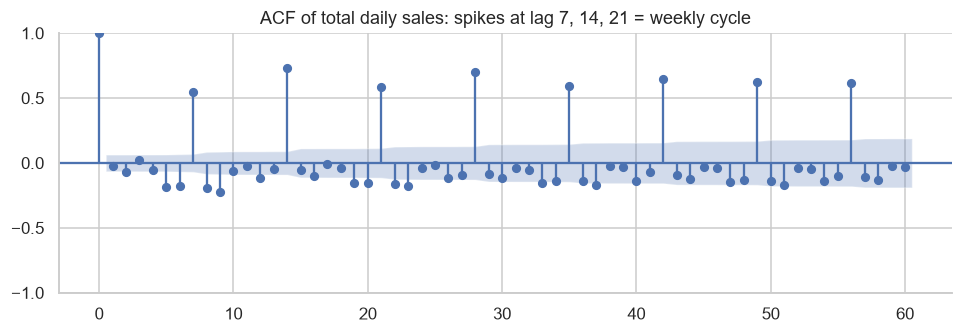

Lag-7 autocorrelation of total sales: 0.55
Monday mean vs Sunday mean (open store-days only): 8,216 vs 8,225; Sunday opening share 2.4% (only large stores open on Sundays)
Highest-mean weekdays among open store-days: ['Sun', 'Mon']
December 2013 vs the 2013 monthly average: +26.2%


In [3]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow = op.groupby("day_of_week").sales.agg(["mean", "count"])
open_share = panel.groupby("day_of_week").open.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(dow_names, by_dow["mean"].reindex(range(1, 8)), color="#2a6f97"); ax[0].set_title("Mean sales per open store-day, by weekday")
ax[1].bar(dow_names, open_share.reindex(range(1, 8)), color="#bc4749"); ax[1].set_title("Share of store-days that are open"); ax[1].set_ylim(0, 1.05)
fig.tight_layout(); fig.savefig(FIG / "eda_weekly.png", dpi=130); plt.show()

monthly = op.assign(year=op.date.dt.year, month=op.date.dt.month).groupby(["year", "month"]).sales.mean().unstack(0)
ax = monthly.plot(marker="o", figsize=(9, 3.8), color=["#adb5bd", "#2a6f97", "#bc4749"])
ax.set_title("Mean sales per open store-day, by month"); ax.set_xticks(range(1, 13)); fig = ax.figure
fig.tight_layout(); fig.savefig(FIG / "eda_yearly.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
plot_acf(daily.total_sales, lags=60, ax=ax); ax.set_title("ACF of total daily sales: spikes at lag 7, 14, 21 = weekly cycle")
fig.tight_layout(); fig.savefig(FIG / "eda_acf.png", dpi=130); plt.show()
acf7 = pd.Series(daily.total_sales.values).autocorr(7)
mon, sun = by_dow["mean"].loc[1], by_dow["mean"].loc[7]
top_days = [dow_names[i - 1] for i in by_dow["mean"].sort_values(ascending=False).index[:2]]
dec_vs_year = monthly.loc[12, 2013] / monthly[2013].mean() - 1
print(f"Lag-7 autocorrelation of total sales: {acf7:.2f}")
print(f"Monday mean vs Sunday mean (open store-days only): {mon:,.0f} vs {sun:,.0f}; Sunday opening share {open_share.loc[7]:.1%} (only large stores open on Sundays)")
print(f"Highest-mean weekdays among open store-days: {top_days}")
print(f"December 2013 vs the 2013 monthly average: {dec_vs_year:+.1%}")

## 3. Promo effect (descriptive)

         mean  median   count
promo                        
0      5930.0  5459.0  467463
1      8229.0  7650.0  376875

Raw lift in the mean (promo vs no promo, all open days): +38.8%

Lift by weekday (promos only run Mon-Fri):
promo               0         1   lift
day_of_week                           
1            6222.728  9772.911  0.571
2            5716.412  8277.631  0.448
3            5617.729  7685.683  0.368
4            5750.883  7598.788  0.321
5            6344.412  7744.388  0.221


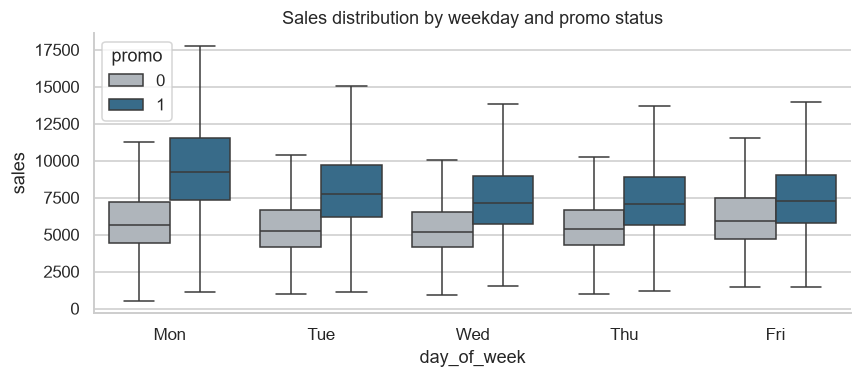

In [4]:
g = op.groupby("promo").sales.agg(["mean", "median", "count"])
raw_lift = g.loc[1, "mean"] / g.loc[0, "mean"] - 1
print(g.round(0).to_string()); print(f"\nRaw lift in the mean (promo vs no promo, all open days): {raw_lift:+.1%}")
by_dow_promo = op.groupby(["day_of_week", "promo"]).sales.mean().unstack()
by_dow_promo["lift"] = by_dow_promo[1] / by_dow_promo[0] - 1
print("\nLift by weekday (promos only run Mon-Fri):"); print(by_dow_promo.dropna().round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(data=op[op.day_of_week <= 5].sample(200_000, random_state=1), x="day_of_week", y="sales", hue="promo",
            showfliers=False, palette=["#adb5bd", "#2a6f97"], ax=ax)
ax.set_xticks(range(5)); ax.set_xticklabels(dow_names[:5]); ax.set_title("Sales distribution by weekday and promo status")
fig.tight_layout(); fig.savefig(FIG / "eda_promo.png", dpi=130); plt.show()

## 4. Holiday effects

In [5]:
st = op.assign(kind=op.state_holiday.map({"0": "none", "a": "public", "b": "Easter", "c": "Christmas"}))
tab = st.groupby("kind").sales.agg(["mean", "count"]); tab["vs_none"] = tab["mean"] / tab.loc["none", "mean"] - 1
print("Open stores on state holidays (note: few stores open on these days):"); print(tab.round(3).to_string())
sch = op.groupby("school_holiday").sales.mean(); school_lift = sch.loc[1] / sch.loc[0] - 1
print(f"\nSchool holiday vs not: {sch.loc[0]:,.0f} -> {sch.loc[1]:,.0f} ({school_lift:+.1%})")
open_by_hol = panel.assign(kind=panel.state_holiday.map({"0": "none", "a": "public", "b": "Easter", "c": "Christmas"})).groupby("kind").open.mean()
print("\nShare of store-days that are open:"); print(open_by_hol.round(3).to_string())

Open stores on state holidays (note: few stores open on these days):
               mean   count  vs_none
kind                                
Christmas  9743.746      71    0.401
Easter     9887.890     145    0.422
none       6953.960  843428    0.000
public     8487.471     694    0.221

School holiday vs not: 6,897 -> 7,201 (+4.4%)

Share of store-days that are open:
kind
Christmas    0.016
Easter       0.022
none         0.828
public       0.034


## 5. Hypothesis test: does a promotion significantly lift sales?

**Design.** Raw promo/no-promo means are confounded: promos only run Mon-Fri, so a naive comparison mixes in
weekday effects, and stores differ hugely in size, so day-level rows are far from independent. The test therefore:

1. keeps only open Mon-Fri days that are not state holidays;
2. for **each store** computes mean sales on promo days and on non-promo days *within each weekday* and averages the
   per-weekday differences (so the weekday mix is identical in both arms);
3. runs a **paired** test across stores (the store is its own control).

Caveat: this is observational, not a randomised experiment. Rossmann sets the promo calendar centrally (it is not
chosen store-by-store in response to demand), which makes timing close to exogenous, but the result is an
association-with-controls, not proven causation.

H0: mean within-store promo lift = 0.  H1: it is not 0 (two-sided, alpha = 0.05).
Effect size: Cohen's d_z of the paired differences, plus the mean % lift with a bootstrap CI.

Stores in test: 1,115
Mean sales  promo: 8,192   no promo: 5,915
Mean paired difference: 2,276 per store-day  (95% CI 2,225 to 2,327)
Mean within-store lift: 39.7%  (bootstrap 95% CI 38.9% to 40.4%)
Paired t-test:  t = 87.0, df = 1114, p = < 1e-300 (underflows to 0)
Wilcoxon signed-rank (robust to non-normality): W = 0, p = 5.88e-184
Effect size Cohen's d_z = 2.61  (large by Cohen's rule of thumb)
Share of stores with a positive lift: 100.0%
Shapiro-Wilk on paired differences: W = 0.962, p = 1.64e-16  -> normality rejected, so lean on the Wilcoxon result (it agrees)


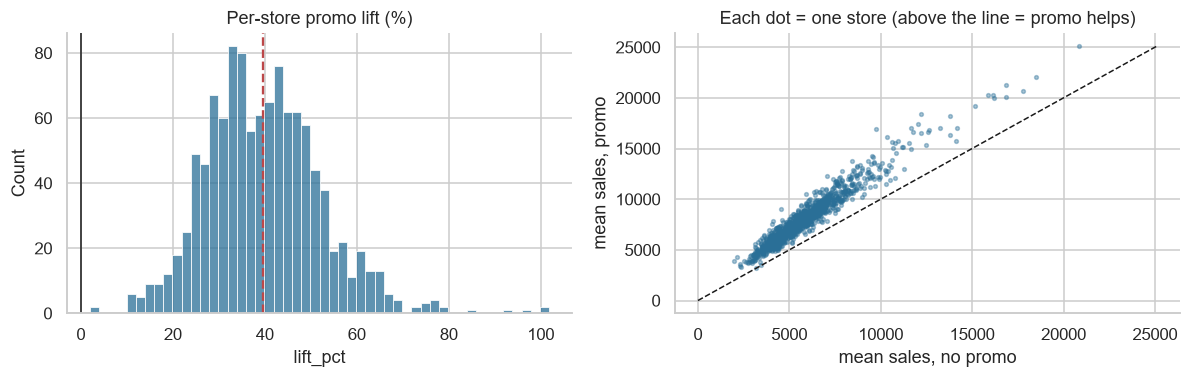

In [6]:
sub = op[(op.day_of_week <= 5) & (op.state_holiday == "0")]
cell = sub.groupby(["store", "day_of_week", "promo"]).sales.mean().unstack("promo").dropna()
cell["diff"] = cell[1] - cell[0]
per_store = cell.groupby("store").agg(promo=(1, "mean"), nopromo=(0, "mean"), diff=("diff", "mean"))
per_store["lift_pct"] = per_store["diff"] / per_store["nopromo"] * 100
n = len(per_store); d = per_store["diff"]

t_stat, p_t = stats.ttest_rel(per_store.promo, per_store.nopromo)
w_stat, p_w = stats.wilcoxon(d)
dz = d.mean() / d.std(ddof=1)
rng = np.random.default_rng(42)
boot = np.array([per_store.lift_pct.sample(n, replace=True, random_state=int(s)).mean() for s in rng.integers(0, 1e9, 2000)])
ci = np.percentile(boot, [2.5, 97.5])
mean_diff_ci = stats.t.interval(0.95, n - 1, loc=d.mean(), scale=stats.sem(d))
sh_stat, sh_p = stats.shapiro(d.sample(min(n, 5000), random_state=1))
print(f"Stores in test: {n:,}")
print(f"Mean sales  promo: {per_store.promo.mean():,.0f}   no promo: {per_store.nopromo.mean():,.0f}")
print(f"Mean paired difference: {d.mean():,.0f} per store-day  (95% CI {mean_diff_ci[0]:,.0f} to {mean_diff_ci[1]:,.0f})")
print(f"Mean within-store lift: {per_store.lift_pct.mean():.1f}%  (bootstrap 95% CI {ci[0]:.1f}% to {ci[1]:.1f}%)")
def fmt_p(p): return "< 1e-300 (underflows to 0)" if p == 0 else f"{p:.3g}"
print(f"Paired t-test:  t = {t_stat:.1f}, df = {n-1}, p = {fmt_p(p_t)}")
print(f"Wilcoxon signed-rank (robust to non-normality): W = {w_stat:,.0f}, p = {p_w:.3g}")
print(f"Effect size Cohen's d_z = {dz:.2f}  ({'large' if abs(dz) >= .8 else 'medium' if abs(dz) >= .5 else 'small'} by Cohen's rule of thumb)")
print(f"Share of stores with a positive lift: {(d > 0).mean():.1%}")
print(f"Shapiro-Wilk on paired differences: W = {sh_stat:.3f}, p = {sh_p:.3g}  -> "
      f"{'normality rejected, so lean on the Wilcoxon result (it agrees)' if sh_p < .05 else 'consistent with normality'}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(per_store.lift_pct, bins=50, color="#2a6f97", ax=ax[0]); ax[0].axvline(0, color="k", lw=1)
ax[0].axvline(per_store.lift_pct.mean(), color="#bc4749", ls="--"); ax[0].set_title("Per-store promo lift (%)")
ax[1].scatter(per_store.nopromo, per_store.promo, s=6, alpha=.4, color="#2a6f97")
m = per_store[["nopromo", "promo"]].values.max(); ax[1].plot([0, m], [0, m], "k--", lw=1)
ax[1].set_xlabel("mean sales, no promo"); ax[1].set_ylabel("mean sales, promo"); ax[1].set_title("Each dot = one store (above the line = promo helps)")
fig.tight_layout(); fig.savefig(FIG / "eda_promo_test.png", dpi=130); plt.show()

**Does the lift depend on store type?** A Kruskal-Wallis test across store types (lift % per store) checks whether
one blanket promo-lift number hides different behaviour by segment.

In [7]:
ps = per_store.join(stores.set_index("store")[["store_type"]])
groups = [g.lift_pct.values for _, g in ps.groupby("store_type")]
h, p_kw = stats.kruskal(*groups)
eps2 = h / (len(ps) - 1)   # epsilon-squared effect size
print(ps.groupby("store_type").lift_pct.agg(["count", "mean", "median"]).round(1).to_string())
print(f"\nKruskal-Wallis H = {h:.1f}, p = {p_kw:.3g}, epsilon^2 = {eps2:.3f}")

            count  mean  median
store_type                     
a             602  38.3    36.7
b              17  20.3    14.6
c             148  40.6    40.3
d             348  42.5    42.0

Kruskal-Wallis H = 53.7, p = 1.29e-11, epsilon^2 = 0.048


**Does a state holiday change sales for stores that are open?** Mann-Whitney U on store-day sales, holiday vs.
ordinary Mon-Fri days (rank-biserial correlation as effect size). Holiday days involve few, atypical stores, so the
comparison is made on each store's *ratio to its own mean*.

In [8]:
op2 = op[op.day_of_week <= 5].copy()
op2["ratio"] = op2.sales / op2.groupby("store").sales.transform("mean")
hol = op2[op2.state_holiday != "0"].ratio; reg = op2[op2.state_holiday == "0"].ratio
u, p_u = stats.mannwhitneyu(hol, reg, alternative="two-sided")
rbc = 1 - 2 * u / (len(hol) * len(reg))   # rank-biserial (negative => holiday values tend to be higher)
print(f"Holiday open-days: {len(hol):,}; ordinary: {len(reg):,}")
print(f"Median sales / own-store mean: holiday {hol.median():.2f} vs ordinary {reg.median():.2f}")
print(f"Mann-Whitney U = {u:,.0f}, p = {p_u:.3g}, rank-biserial r = {-rbc:+.2f} (positive => holiday sales higher)")

Holiday open-days: 902; ordinary: 695,791
Median sales / own-store mean: holiday 1.02 vs ordinary 0.97
Mann-Whitney U = 318,046,911, p = 0.482, rank-biserial r = +0.01 (positive => holiday sales higher)


## 6. Takeaways (printed from the numbers above)

In [9]:
print(f"1. Trend: like-for-like Jan-Jul sales per open store-day moved {', '.join(f'{int(k)}: {v:+.1%}' for k, v in growth.items())}.")
print(f"2. Weekly cycle is strong (lag-7 autocorrelation {acf7:.2f}); Sunday is mostly closed ({open_share.loc[7]:.0%} open) "
      f"and the highest-mean days per open store are {' and '.join(top_days)}.")
print(f"3. Promos: within-store lift {per_store.lift_pct.mean():.1f}% (95% CI {ci[0]:.1f}-{ci[1]:.1f}%), "
      f"paired t p={fmt_p(p_t)}, Cohen's d_z={dz:.2f}; {(d>0).mean():.0%} of stores benefit. Promo (and the weekday it falls on) must be a model input.")
print(f"4. Promo lift differs by store type (Kruskal-Wallis p={p_kw:.2g}, epsilon^2={eps2:.3f}); store attributes belong in the model.")
print(f"5. Holidays: only {open_by_hol[['public','Easter','Christmas']].min():.1%}-{open_by_hol[['public','Easter','Christmas']].max():.1%} of stores open on state holidays; "
      f"for those that do, sales relative to their own mean are not significantly different (Mann-Whitney p={p_u:.2f}). "
      f"The holiday effect on a forecast is mostly the open/closed flag, which is a known input.")
print(f"6. Seasonality: Christmas-season spike: December 2013 is {dec_vs_year:+.1%} above the 2013 monthly average; yearly lags/calendar features are needed.")

1. Trend: like-for-like Jan-Jul sales per open store-day moved 2014: +2.6%, 2015: +3.1%.
2. Weekly cycle is strong (lag-7 autocorrelation 0.55); Sunday is mostly closed (2% open) and the highest-mean days per open store are Sun and Mon.
3. Promos: within-store lift 39.7% (95% CI 38.9-40.4%), paired t p=< 1e-300 (underflows to 0), Cohen's d_z=2.61; 100% of stores benefit. Promo (and the weekday it falls on) must be a model input.
4. Promo lift differs by store type (Kruskal-Wallis p=1.3e-11, epsilon^2=0.048); store attributes belong in the model.
5. Holidays: only 1.6%-3.4% of stores open on state holidays; for those that do, sales relative to their own mean are not significantly different (Mann-Whitney p=0.48). The holiday effect on a forecast is mostly the open/closed flag, which is a known input.
6. Seasonality: Christmas-season spike: December 2013 is +26.2% above the 2013 monthly average; yearly lags/calendar features are needed.


In [10]:
import json
stats_out = {
    "promo_test": {"n_stores": int(n), "mean_sales_promo": float(per_store.promo.mean()), "mean_sales_nopromo": float(per_store.nopromo.mean()),
                   "mean_lift_pct": float(per_store.lift_pct.mean()), "lift_ci95": [float(ci[0]), float(ci[1])],
                   "t_stat": float(t_stat), "p_ttest": float(p_t), "p_wilcoxon": float(p_w), "cohens_dz": float(dz),
                   "share_stores_positive": float((d > 0).mean())},
    "promo_by_store_type": {"kruskal_H": float(h), "p": float(p_kw), "epsilon_sq": float(eps2),
                            "mean_lift_by_type": {k: float(v) for k, v in ps.groupby("store_type").lift_pct.mean().items()}},
    "state_holiday_test": {"p_mannwhitney": float(p_u), "median_ratio_holiday": float(hol.median()), "median_ratio_ordinary": float(reg.median())},
    "trend": {"yoy_like_for_like": {int(k): float(v) for k, v in growth.items()}},
    "seasonality": {"acf_lag7": float(acf7), "december_2013_vs_year_avg": float(dec_vs_year), "sunday_open_share": float(open_share.loc[7])},
}
(ROOT / "reports" / "eda_stats.json").write_text(json.dumps(stats_out, indent=2))
print("saved reports/eda_stats.json")

saved reports/eda_stats.json
